# 수수컴정 중간발표 결과 확인

최종 발표 범위는 Dummy와 TF-IDF 기준선이다. 최빈값 Dummy의 macro-F1은 **0.427**, 무작위 Dummy는 **0.495**다. TF-IDF + Logistic Regression은 댓글만 **0.647**, 맥락+댓글 **0.633**이며, 맥락 조건의 임계값을 조정하면 **0.662**다.

원실험: 소지연 / 확장·임계값 비교: 안지수 / 통합·CPU 재현·이 노트북: 진군학.
제공 CSV와 WSL CPU 재현 결과를 대조했다. 이전 PLM CSV는 참고용으로 보존하며 이번 발표 표·그림에서는 제외한다. 이 노트북은 추가 학습이나 Notion 업로드를 하지 않는다.

## 조건과 데이터

KOCOH v2 3,000행, 혐오 764 / 비혐오 2,236. 같은 Context를 공유하는 Set을 합친 77개 post_group으로 바깥 5-fold를 만들었다(seed 42). TF-IDF 임계값은 바깥 train의 내부 묶음 4-fold OOF에서 고른 뒤 train 전체로 재학습한다. OOF는 각 행을 학습에 사용하지 않은 모델이 만든 예측이다.

표의 SD는 **5개 test fold 사이의 표본 표준편차(ddof=1)**다. seed 반복이나 신뢰구간이 아니다.

저장소 루트 또는 `notebooks/`에서 실행한다. 결과 읽기에는 데이터·가중치가 필요 없으며, CPU 학습 재현 명령은 README에 있다.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from scipy import stats
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'results/midterm').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'results/midterm/provided').is_dir(), '저장소 루트 또는 notebooks에서 실행하세요.'
sys.path.insert(0, str(ROOT))
from src.midterm.summarize import main, tables
main()
base, tuned, summary, thresholds = tables()
print('기준선 fold별 결과:', len(base), '+', len(tuned), '=', len(base)+len(tuned), '행')
print('기본 임계값 결과가 일부 중복되므로 독립 학습 110회를 뜻하지 않습니다.')

표 2개 및 PNG/PDF 그림 2쌍 저장 완료
기준선 fold별 결과: 50 + 60 = 110 행
기본 임계값 결과가 일부 중복되므로 독립 학습 110회를 뜻하지 않습니다.


## 입력 조건별 비교

,model,method,condition,macro_f1_mean,macro_f1_std,recall_hate_mean,recall_hate_std
0,Dummy most_frequent,default threshold,-,0.427,0.005,0.000,0.000
1,Dummy stratified,default threshold,-,0.495,0.024,0.263,0.033
3,TF-IDF LogReg,default threshold,Comment-only,0.647,0.014,0.528,0.045
4,TF-IDF LinearSVC,default threshold,Comment-only,0.644,0.014,0.500,0.031
6,TF-IDF LogReg,default threshold,Context+Comment,0.633,0.033,0.303,0.031
7,TF-IDF LinearSVC,default threshold,Context+Comment,0.618,0.034,0.250,0.051
8,TF-IDF LogReg,default threshold,Context-only,0.465,0.077,0.162,0.091
9,TF-IDF LinearSVC,default threshold,Context-only,0.508,0.057,0.136,0.088


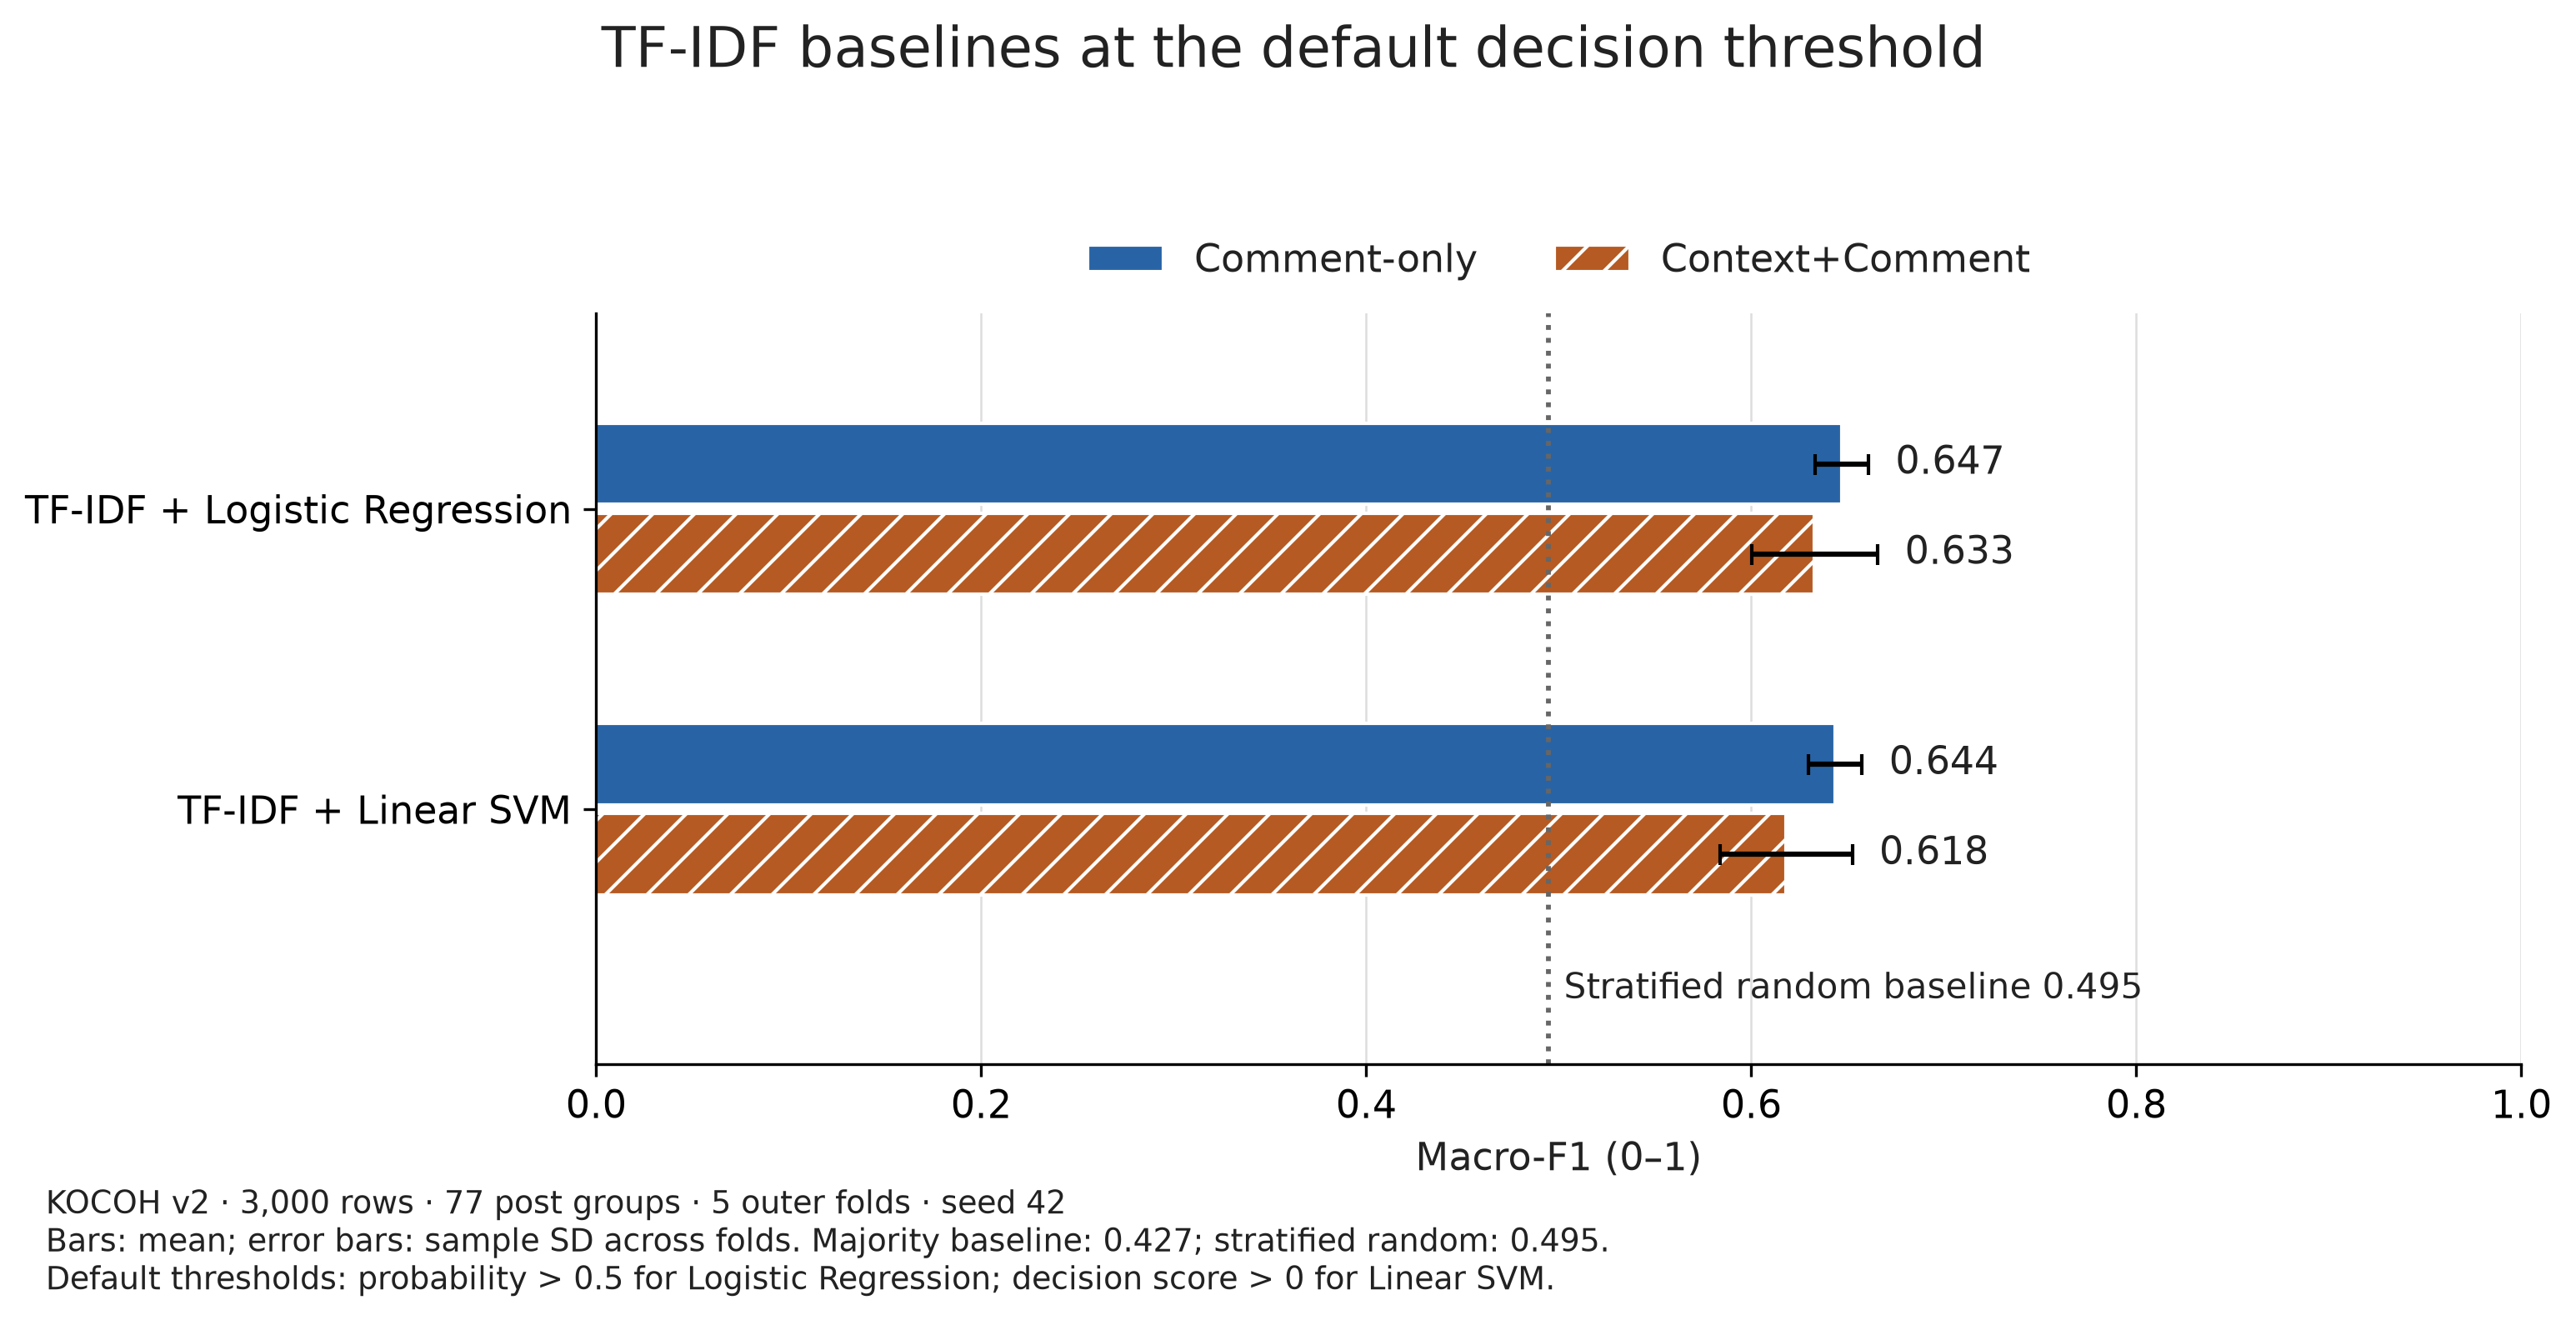

,model,mean_delta,sd_delta,improved_folds,paired_t_p
0,TF-IDF LogReg,-0.014,0.033,2,0.388
1,TF-IDF LinearSVC,-0.025,0.028,0,0.114


In [2]:
selection = summary[summary['model'].isin(['Dummy most_frequent','Dummy stratified','TF-IDF LogReg','TF-IDF LinearSVC'])]
display(selection.round(3))
display(Image(filename=str(ROOT/'figures/midterm/01_context_comparison.png'), width=950))
comparisons = []
for model in ['TF-IDF LogReg', 'TF-IDF LinearSVC']:
    paired = base[base.model == model].pivot(index='fold', columns='condition', values='macro_f1')
    delta = paired['Context+Comment'] - paired['Comment-only']
    comparisons.append({'model': model, 'mean_delta': delta.mean(), 'sd_delta': delta.std(ddof=1),
                        'improved_folds': int((delta > 0).sum()),
                        'paired_t_p': stats.ttest_rel(paired['Context+Comment'], paired['Comment-only']).pvalue})
display(pd.DataFrame(comparisons).round(3))

기본 규칙에서 맥락을 추가하면 Logistic Regression은 0.647 → 0.633, Linear SVM은 0.644 → 0.618이었다. 양의 맥락 효과를 확인하지 못했다. 맥락만 입력한 결과도 각각 0.465와 0.508로 무작위 Dummy 0.495 부근이었다.

보고서는 최소 기준선으로 최빈값 Dummy를, 발표자료는 비교용으로 무작위 Dummy를 사용한다. 두 숫자의 의미를 구별한다.

## TF-IDF 임계값 조정

,model,condition,rule,macro_f1_mean,macro_f1_std,recall_hate_mean,recall_hate_std,pr_auc_mean,pr_auc_std
0,TF-IDF LogReg,Comment-only,0.5 고정,0.647,0.014,0.528,0.045,0.437,0.021
1,TF-IDF LogReg,Comment-only,OOF 조정,0.644,0.013,0.588,0.064,0.437,0.021
4,TF-IDF LogReg,Context+Comment,0.5 고정,0.633,0.033,0.303,0.031,0.524,0.058
5,TF-IDF LogReg,Context+Comment,OOF 조정,0.662,0.027,0.535,0.038,0.524,0.058


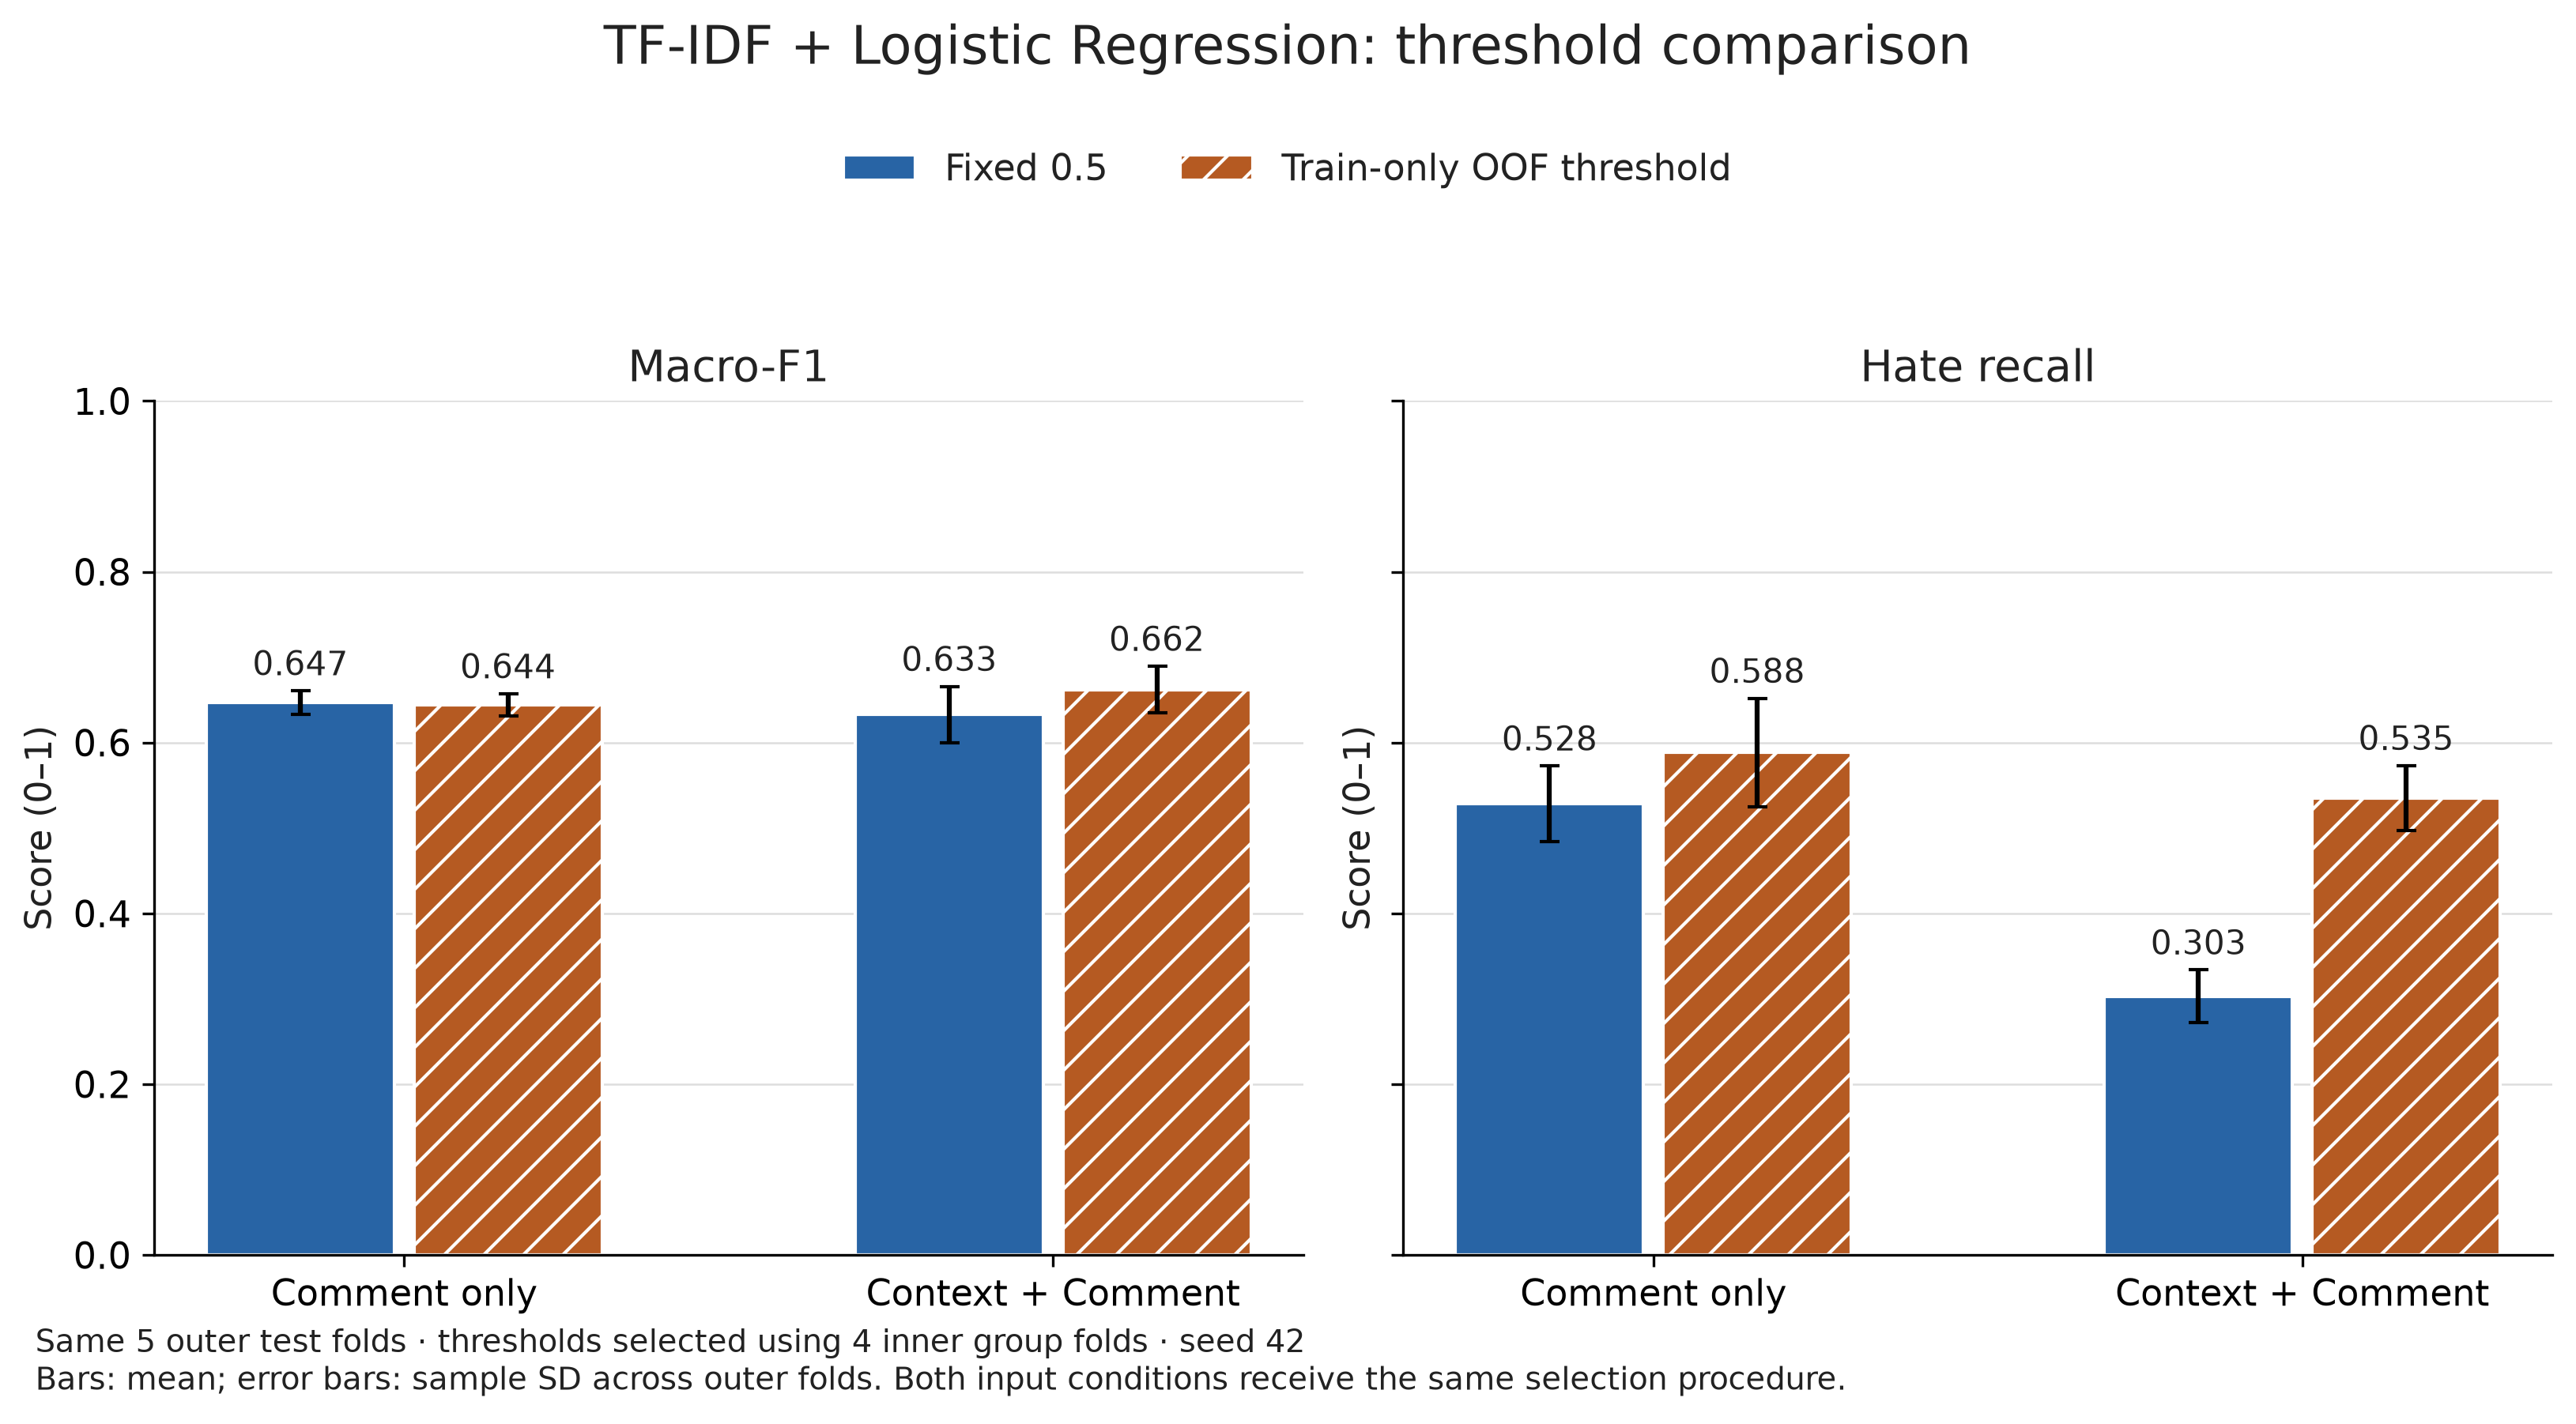

In [3]:
display(thresholds[(thresholds.model=='TF-IDF LogReg') & (thresholds.condition!='Context-only')].round(3))
display(Image(filename=str(ROOT/'figures/midterm/02_threshold_comparison.png'), width=950))

두 입력 조건 모두 같은 내부 검증 절차를 적용했다. 맥락 조건의 Recall은 0.303 → 0.535, 댓글만 조건은 0.528 → 0.588이다. 따라서 조정 후 맥락 추가에 따른 Recall 차이는 −0.053이다. `pr_auc` 열은 sklearn의 **average precision(AP)** 계산값이며 사다리꼴 적분 PR-AUC와 구별한다.

## 재현 확인과 해석의 한계

In [4]:
check = json.loads((ROOT/'results/midterm/validation.json').read_text())
checks = pd.DataFrame(check['csv_comparisons'])
display(checks[checks.file != 'plm_folds.csv'])
display(pd.read_csv(ROOT/'results/midterm/comment_oracle_check.csv').round(6))
print('댓글별 고정 라벨의 사후 최댓값, fold 평균:', round(check['comment_oracle_mean'], 6))

,file,status,rows
1,baseline_folds.csv,match_atol_1e-6,40
2,baseline_v2_folds.csv,match_atol_1e-6,50
3,baseline_v2_by_type.csv,match_atol_1e-6,120
4,comment_only_ceiling.csv,match_atol_1e-6,5
5,baseline_v3_folds.csv,match_atol_1e-6,60
6,baseline_v3_by_type.csv,match_atol_1e-6,240
7,split_assignment_v2.csv,match_atol_1e-6,15000
8,inner_val_composition.csv,match_atol_1e-6,20


,fold,macro_f1,tp,fp
0,0,0.709737,165,165
1,1,0.739097,152,151
2,2,0.735897,152,152
3,3,0.734685,146,146
4,4,0.730536,147,147


댓글별 고정 라벨의 사후 최댓값, fold 평균: 0.729991


- 약 0.730은 이 데이터와 5개 fold에서 같은 댓글에 같은 답을 내는 결정론적 규칙의 사후 최댓값이다. test 정답을 사용한 계산이므로 학습 모델의 성능이나 일반적인 혐오탐지 상한이 아니다. 이 값을 넘는 것만으로 맥락 이해가 입증되지는 않는다.
- fold들은 학습 데이터를 공유한다. 대응표본 t-검정 p값은 탐색적 근거로 보며 5개의 독립 실험으로 해석하지 않는다. [Bengio & Grandvalet (2004)](https://www.jmlr.org/papers/v5/grandvalet04a.html).
- 10주차: KcELECTRA-base-v2022와 KLUE-RoBERTa-base 학습·seed 3회 반복, 확률 저장, 맥락만 입력하는 조건, Colab T4 시간 확인, 발표 피드백 반영.
- 11주차: PLM 임계값 조정·유형별 오류 분석·LoRA 비교와 최종 정리. 일정은 최종 발표자료를 따른다.